
# 3D demo : Passive cavitation imaging(PyCav)
This notebook demonstrate the use of `pycav` for passive acoustic mapping (DAS, RCB, FB, et CMF-spTV).



In [1]:
# Seulement pour tester le colab avec le projet privé. Il faut créer un token sur github.
# Pour cela il faut aller dans settings > Developers settings (tout en bas à gauche) > personnal access tokens >tokens (classic).
# Cocher repo en scope.
# Ensuite, dans colab, il faut aller dans Secrets (la clé à droite), et coller la clé. Donner en nom 'GH_token' (ou changer dans
# le code ci-dessous.

import os
from google.colab import userdata

# Récupère le token de façon sécurisée
gh_token = userdata.get('GH_token')

# Ton nom d'utilisateur GitHub
username = "celest-la"
repo_name = "private-pycav"

# Construit l'URL sécurisée et clone le repo
repo_url = f"https://{gh_token}@github.com/{username}/{repo_name}.git"

# On utilise os.system pour ne pas afficher le token dans les logs de sortie si ça plante
os.system(f"git clone {repo_url}")

# On se déplace dans le dossier et on installe
%cd {repo_name}
!pip install -q -e .

/content/private-pycav
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for PyCav (pyproject.toml) ... done


In [11]:
import sys
chemin_src = '/content/private-pycav/src'

if chemin_src not in sys.path:
    sys.path.insert(0, chemin_src)


In [ ]:
import torch
import gc
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# GPU optimization
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.set_default_dtype(torch.float32)

# Material verification
if torch.cuda.is_available():
    device = "cuda"
    gpu_name = torch.cuda.get_device_name(0)
else:
    device = "cpu"

# PyCav Imports
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from pycav.core.probe import Probe
from pycav.core.grid import Grid
from pycav.solvers.beamformers import DAS, RCB, FB, CMFspTV
from pycav.simulation.simulation import BBagSimulator, getPositions
from pycav.solvers.preproc import compute_csm
from pycav.utils.io import plot_result_3d_mip_dB, plot_bubble_positions_3d, plot_volume_3d_voxels_dB, Timer

In [ ]:
print("Probe and Grid configuration...")
mat_file = "src/pycav/utils/matrix1024.mat"
probe = Probe.from_matlab_file(mat_file, struct_name='param', device=device)

# Create a 3D Imaging Grid [Nx x Ny x Nz]
grid = Grid.from_limits_3d(
    x_lim=(-5e-3, 5e-3),  # 1 cm width
    y_lim=(-5e-3, 5e-3),  # 1 cm height
    z_lim=(10e-3, 30e-3),   # 1 cm depth
    step=0.2e-3,            # 0.2 mm step
    device=device
)
print(f"3D Probe Elements : {probe.n_elements}")
print(f"3D Grid Voxels     : {grid.n_pixels} (Shape: {grid.shape})")

Probe and Grid configuration...
RF signal simulation..
RF ready


In [ ]:
# 3. 3D BUBBLE CLOUD SIMULATION
# Generate 3D bubble positions within an ellipsoid centered at z=20mm
positions, center, axes = getPositions.random_ellipsoid(
    x_position_lim=0.5e-3,
    y_position_lim=1.0e-3,
    z_position_lim=22e-3,
    x_size_lim=2.0e-3,
    y_size_lim=1.0e-3,
    z_size_lim=3.0e-3,
    density=1000,
    device=device
)

c0 = 1480.0
fhifu = 1.0e6

sim = BBagSimulator(probe, positions, fhifu=fhifu, device=device, c0=c0)
rf_data = sim.simulate(t_acq=4e-4, n_cycles=150, noise_level=0.001, batch_size=500)

# CLEAR PYTORCH CUDA CACHE after simulation to free up memory for reconstruction
torch.cuda.empty_cache()
del sim

plot_bubble_positions_3d(positions, grid, title="3D Bubble Cloud Simulation")
# Compute Cross-Spectral Matrix (CSM)


In [ ]:
csm, freqs = compute_csm(rf_data, probe, K=80, overlap=0.8, f=[3.5e6])

# 4. 3D RECONSTRUCTION WITH SOLVERS
das = DAS(probe, grid, c=c0)
rcb = RCB(probe, grid, c=c0)
fb = FB(probe, grid, c=c0)
cmf = CMFspTV(probe, grid, c=c0)

options_cmf = {
    'max_iter': 200,
    'verbose': True,
    'warm_start': True,
    'adaptive_step': False
}

print("\n--- Running 3D Solvers ---")
torch.cuda.empty_cache()
print("1. DAS 3D...")
with Timer("DAS 3D", device=device):
    img_das = das.solve(csm, freqs, average=True)
torch.cuda.empty_cache()
print("2. RCB 3D...")
with Timer("RCB 3D", device=device):
    img_rcb = rcb.solve(csm, freqs, epsilon=5, average=True)
torch.cuda.empty_cache()
print("3. FB (PISA) 3D...")
with Timer("FB 3D", device=device):
    img_fb = fb.solve(csm, freqs, r=0, average=True)

torch.cuda.empty_cache()
print("4. CMF-spTV 3D...")
with Timer("CMF-spTV 3D", device=device):
    img_cmf = cmf.solve(
        csm, 
        freqs, 
        rel_lambda_l1=0.4, 
        rel_lambda_tv_x=0.25, 
        rel_lambda_tv_y=0.25, 
        rel_lambda_tv_z=0.03,
        options=options_cmf, 
    average=True
)

--- 2D reconstruction in process ---
[DAS] Execution time: 2.79 ms (0.003 s)
[RCB] Execution time: 16.36 ms (0.016 s)
[FB] Execution time: 6.66 ms (0.007 s)
Initialisation : Warm-Start (DAS physique).
--- CMF-spTV Configuration ---
Sonde d'imagerie    : 128 éléments
Grille d'imagerie    : (102, 102) pixels
Calcul de lambda_max : 2.088809e-01
lambda_l1 absolue     : 6.266427e-02
lambda_tv_x absolue  : 5.222023e-02
lambda_tv_y absolue : 5.222023e-02
lambda_tv_z absolue : 6.266427e-03
------------------------------
Iteration 50/100 | Residu : 2.736189e+00
Iteration 100/100 | Residu : 1.332059e+00
[CMF-spTV] Execution time: 181.77 ms (0.182 s)


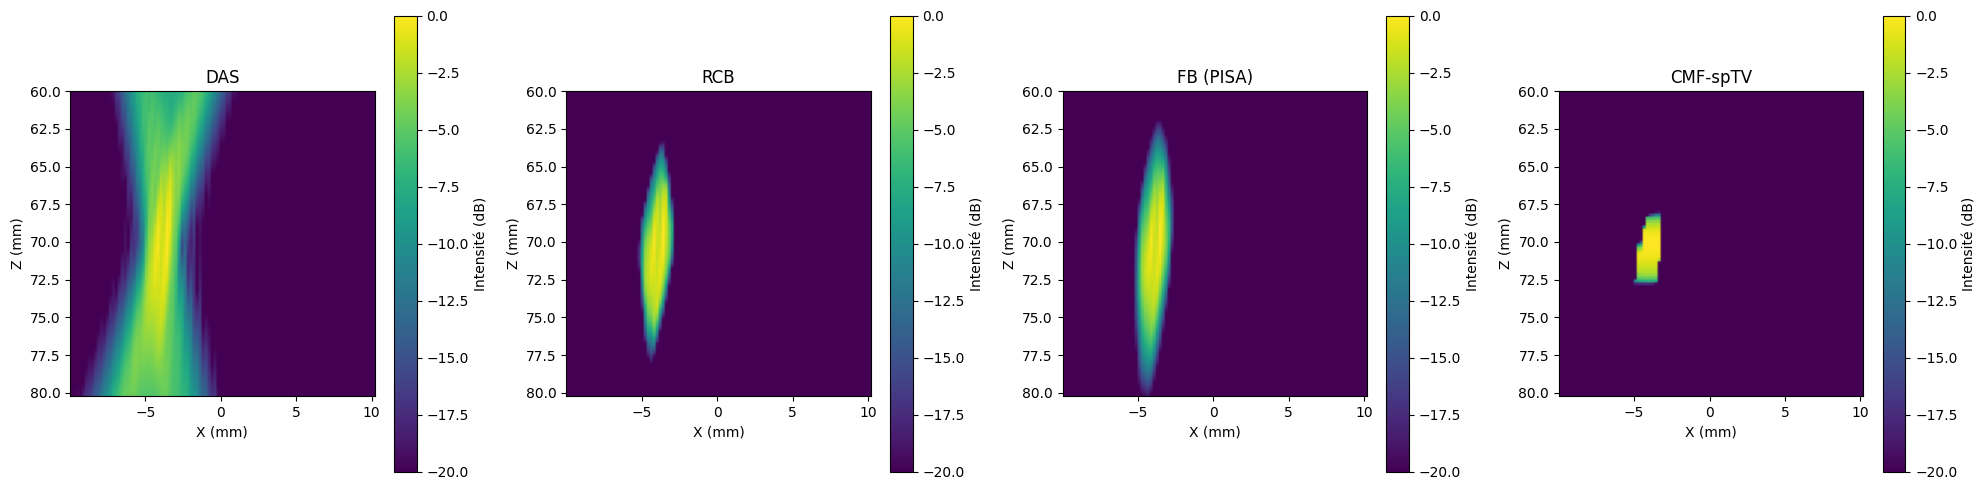

In [ ]:
# 5. VISUALIZATION (Maximum Intensity Projections - MIP for XZ, YZ, XY planes)
plot_result_3d_mip_dB(img_das, grid, title="3D DAS Reconstruction (MIP)", dynamic_range=10)
plot_result_3d_mip_dB(img_rcb, grid, title="3D RCB Reconstruction (MIP)", dynamic_range=10)
plot_result_3d_mip_dB(img_fb, grid, title="3D FB (PISA) Reconstruction (MIP)", dynamic_range=10)
#plot_volume_3d_voxels_dB(img_cmf, grid, title="CMF-spTV 3D Bubble Cloud", threshold_dB=-12.0)
#plot_volume_3d_voxels_dB(img_cmfa, grid, title="CMF-spTV Adaptive 3D Bubble Cloud", threshold_dB=-12.0)
#plot_volume_3d_voxels_dB(img_fb, grid, title="FB 3D Bubble Cloud", threshold_dB=-12.0)
plot_volume_3d_voxels_dB(img_rcb, grid, title="RCB 3D Bubble Cloud", threshold_dB=-12.0)
plt.show()